In [82]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import pyabc
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

from plotting_tools import * 

In [83]:
plot_path = f"../plots/ww_fits"
os.makedirs(plot_path, exist_ok=True)

In [84]:
db_path = f"../../1_estimation/output/HEV_ww.db"
history = pyabc.History("sqlite:///" + db_path)

In [85]:
obs = pd.read_csv(f"../../0_data/ww.csv", sep=",", index_col=False)

obs = obs.loc[:, ["Sample ID", "Name", "Date", "Comment WW", "HEV per 5 µL", "PMMoV (Cp)"]]

obs = obs.map(lambda v: pd.NA if isinstance(v, str) and '-' in v else v)
obs = obs.replace({"": pd.NA})
obs = obs.replace({"n.d.": 0})

obs = obs.dropna(subset=["PMMoV (Cp)"])
exclude_ids = {"2095","2136","2099","2138","2105","2131","2119","2137","2122","2139","2107","2132","2134","2295"}
obs = obs[~obs["Sample ID"].astype(str).isin(exclude_ids)]

obs.loc[obs["Name"].str.lower() == "schmidbartlanger", "Name"] = "Schmidbartlanger"
obs = obs[obs["Name"].isin(["Schmidbartlanger", "24h Probe"])]

s = obs["Date"].astype(str).str.strip()
obs["Date"] = pd.to_datetime(s, format="%m/%d/%y", errors="coerce")
mask = obs["Date"].isna()
obs.loc[mask, "Date"] = pd.to_datetime(s[mask], format="%m/%d/%Y", errors="coerce")

for col in ["HEV per 5 µL", "PMMoV (Cp)"]:
    obs[col] = pd.to_numeric(obs[col].astype(str).str.replace(",", "", regex=False),errors="coerce")

obs["ConcF"] = np.where(obs["Comment WW"] == "frozen", 38 * 2 / 0.06, 38 / 0.06)
obs["HEV_L"] = obs["HEV per 5 µL"] * 1000 / (0.005 * obs["ConcF"])

obs["PMMoV_1µL"] = 1.972 ** (39.65 - obs["PMMoV (Cp)"])
obs["PMMoV_L"]   = obs["PMMoV_1µL"] * 1000 / (0.001 * obs["ConcF"])

obs["PMMoV_mean"] = np.where(obs["Name"] == "24h Probe", 6_500_000, np.where(obs["Comment WW"] == "fresh", 15_000_000, 8_300_000))
obs["Norm"] = obs["PMMoV_mean"] / obs["PMMoV_L"]

obs["HEV_c"] = obs["HEV_L"] * obs["Norm"]

obs["Category"] = "Non-Emergency"
mask1 = (obs["Date"] >= pd.to_datetime("12/09/2020", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("06/06/2021", format="%m/%d/%Y"))
mask2 = (obs["Date"] >= pd.to_datetime("11/11/2021", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("05/11/2022", format="%m/%d/%Y"))
obs.loc[mask1 | mask2, "Category"] = "Emergency"


In [86]:
rows = []
for p in range(0, history.max_t + 1):
    particles = history.get_population(p).get_particles_by_model()[0]
    for particle in particles[:200]:
        rows.append({
            "distance": particle.distance,
            "population": (p + 1)
        })

df_dist = pd.DataFrame(rows)

all_pops = history.get_all_populations()
df = all_pops.T
samples = df.loc[df.index == "samples"]
samples = samples.transpose()
samples["population"] = range(0, history.max_t + 2, 1)
samples["Acceptance rate"] = 200 / samples["samples"] * 100  # 2.4, 1.5, 0.8, 0.6
samples["samples_scaled"] = samples["samples"] / 1e4
samples = samples.drop(0)


In [87]:
all_pops = pd.concat([all_pops, all_pops["population_end_time"].shift()], axis=1).dropna()
all_pops.columns = ["t", "end_time", "samples", "epsilon", "particles", "start_time"]
all_pops['diff_minutes'] = (all_pops['end_time'] - all_pops['start_time']).dt.total_seconds() / 60
print(all_pops)

     t                   end_time  samples   epsilon  particles  \
1    0 2025-10-01 18:20:56.734621      495  2.028216        200   
2    1 2025-10-01 19:33:31.487299      576  1.779762        200   
3    2 2025-10-01 20:37:40.282719      496  1.569471        200   
4    3 2025-10-01 21:53:58.858500      598  1.439095        200   
5    4 2025-10-01 23:28:01.315861      739  1.314961        200   
6    5 2025-10-02 01:13:29.379674      824  1.232008        200   
7    6 2025-10-02 03:12:57.658314      954  1.155136        200   
8    7 2025-10-02 05:58:21.267331     1311  1.080392        200   
9    8 2025-10-02 09:08:43.755506     1520  1.032171        200   
10   9 2025-10-02 13:10:56.916046     1931  0.961834        200   
11  10 2025-10-02 19:01:07.029967     2804  0.903400        200   
12  11 2025-10-03 02:12:50.100552     3458  0.844052        200   
13  12 2025-10-03 09:44:43.256460     3618  0.807285        200   
14  13 2025-10-03 19:35:45.670289     4735  0.770673        20

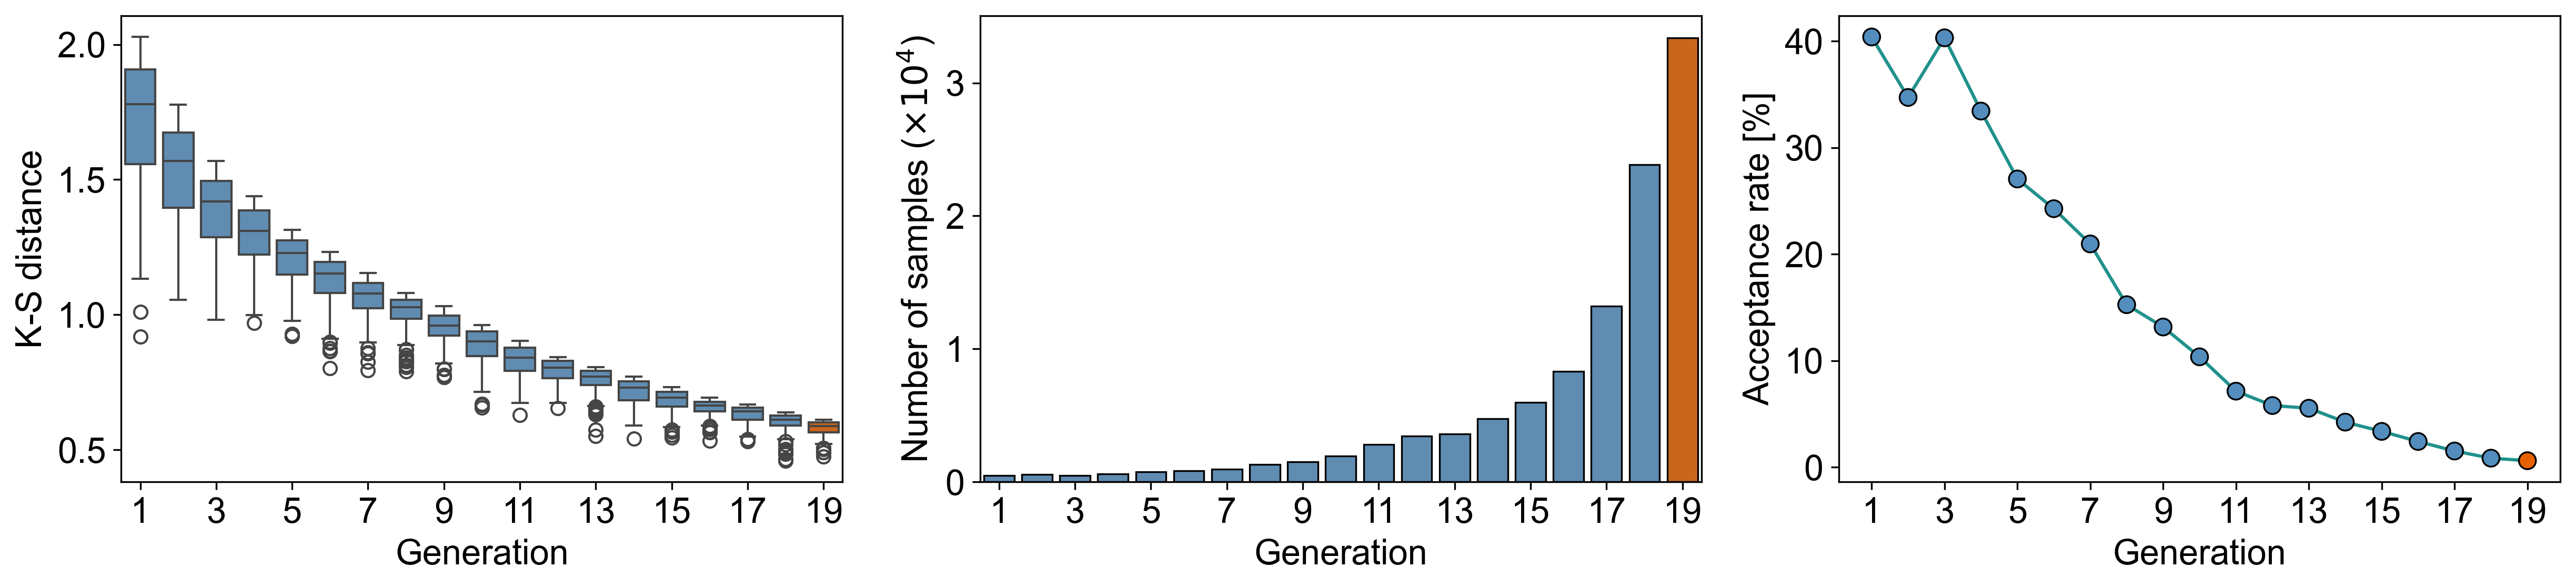

In [88]:
plt.style.use('default')
set_fontsize()

fig, axes = plt.subplots(figsize = (16.6,4), nrows=1, ncols=3, dpi=300)

unique_pops = sorted(df_dist["population"].unique())
palette = {pop: (orange if pop == 19 else lightblue) for pop in unique_pops}

sns.boxplot(data = df_dist, x = "population", y = "distance", hue = "population", legend = False, palette = palette, ax = axes[0])
axes[0].set_ylabel("K-S distance")
axes[0].set_xlabel("Generation")
axes[0].set_xticks(range(0, len(unique_pops), 2))

sns.barplot(data = samples, x = 'population', y = 'samples_scaled', hue = "population", legend = False, palette = palette, ax = axes[1])
for patch in axes[1].patches:
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
axes[1].set_ylabel(r"Number of samples ($\times 10^{4}$)")
axes[1].set_xlabel("Generation")
axes[1].set_xticks(range(0, len(unique_pops), 2))
#axes[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

means = (samples.groupby('population', as_index=False)['Acceptance rate'].mean().sort_values('population'))
axes[2].plot(means['population'], means['Acceptance rate'], linewidth=1.5, c = teal, zorder=1)
sns.scatterplot(data=samples, x='population', y='Acceptance rate', hue = "population", legend = False, ax = axes[2], palette = palette, marker='o', edgecolor='black', linewidth=0.8, s=60, zorder=2)
axes[2].set_xlabel("Generation")
axes[2].set_xticks(range(1, len(unique_pops) + 1, 2))
axes[2].set_ylabel("Acceptance rate [%]")

plt.tight_layout()
plt.savefig(f"{plot_path}/generations.png", dpi=300)
plt.show()

In [89]:
p = history.max_t

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["GG_nl"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_GG_nl = pd.DataFrame(rows)
sim_GG_nl["Name"] = "24h Probe"
sim_GG_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["GG_l"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_GG_l = pd.DataFrame(rows)
sim_GG_l["Name"] = "24h Probe"
sim_GG_l["Category"] = "Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["S_nl"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_S_nl = pd.DataFrame(rows)
sim_S_nl["Name"] = "Schmidbartlanger"
sim_S_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["S_l"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_S_l = pd.DataFrame(rows)
sim_S_l["Name"] = "Schmidbartlanger"
sim_S_l["Category"] = "Emergency"

sim = pd.concat([sim_GG_nl, sim_GG_l, sim_S_nl, sim_S_l], ignore_index=True)
sim["ww_scaled"] = sim["ww"] / 1e5

In [90]:
def compute_ecdf_band(df, x_grid, x_max):
    particle_ecdfs = []
    for pid, group in df.groupby("particle"):
        x = np.sort(group["ww_scaled"])
        y = np.arange(1, len(x) + 1) / len(x)
        x = np.append(x, x_max)
        y = np.append(y, 1.0)
        y_interp = np.interp(x_grid, x, y)
        particle_ecdfs.append(y_interp)

    particle_ecdfs = np.vstack(particle_ecdfs)
    lower = np.percentile(particle_ecdfs, 2.5, axis=0)
    mean = np.mean(particle_ecdfs, axis=0)
    upper = np.percentile(particle_ecdfs, 97.5, axis=0)
    return lower, mean, upper

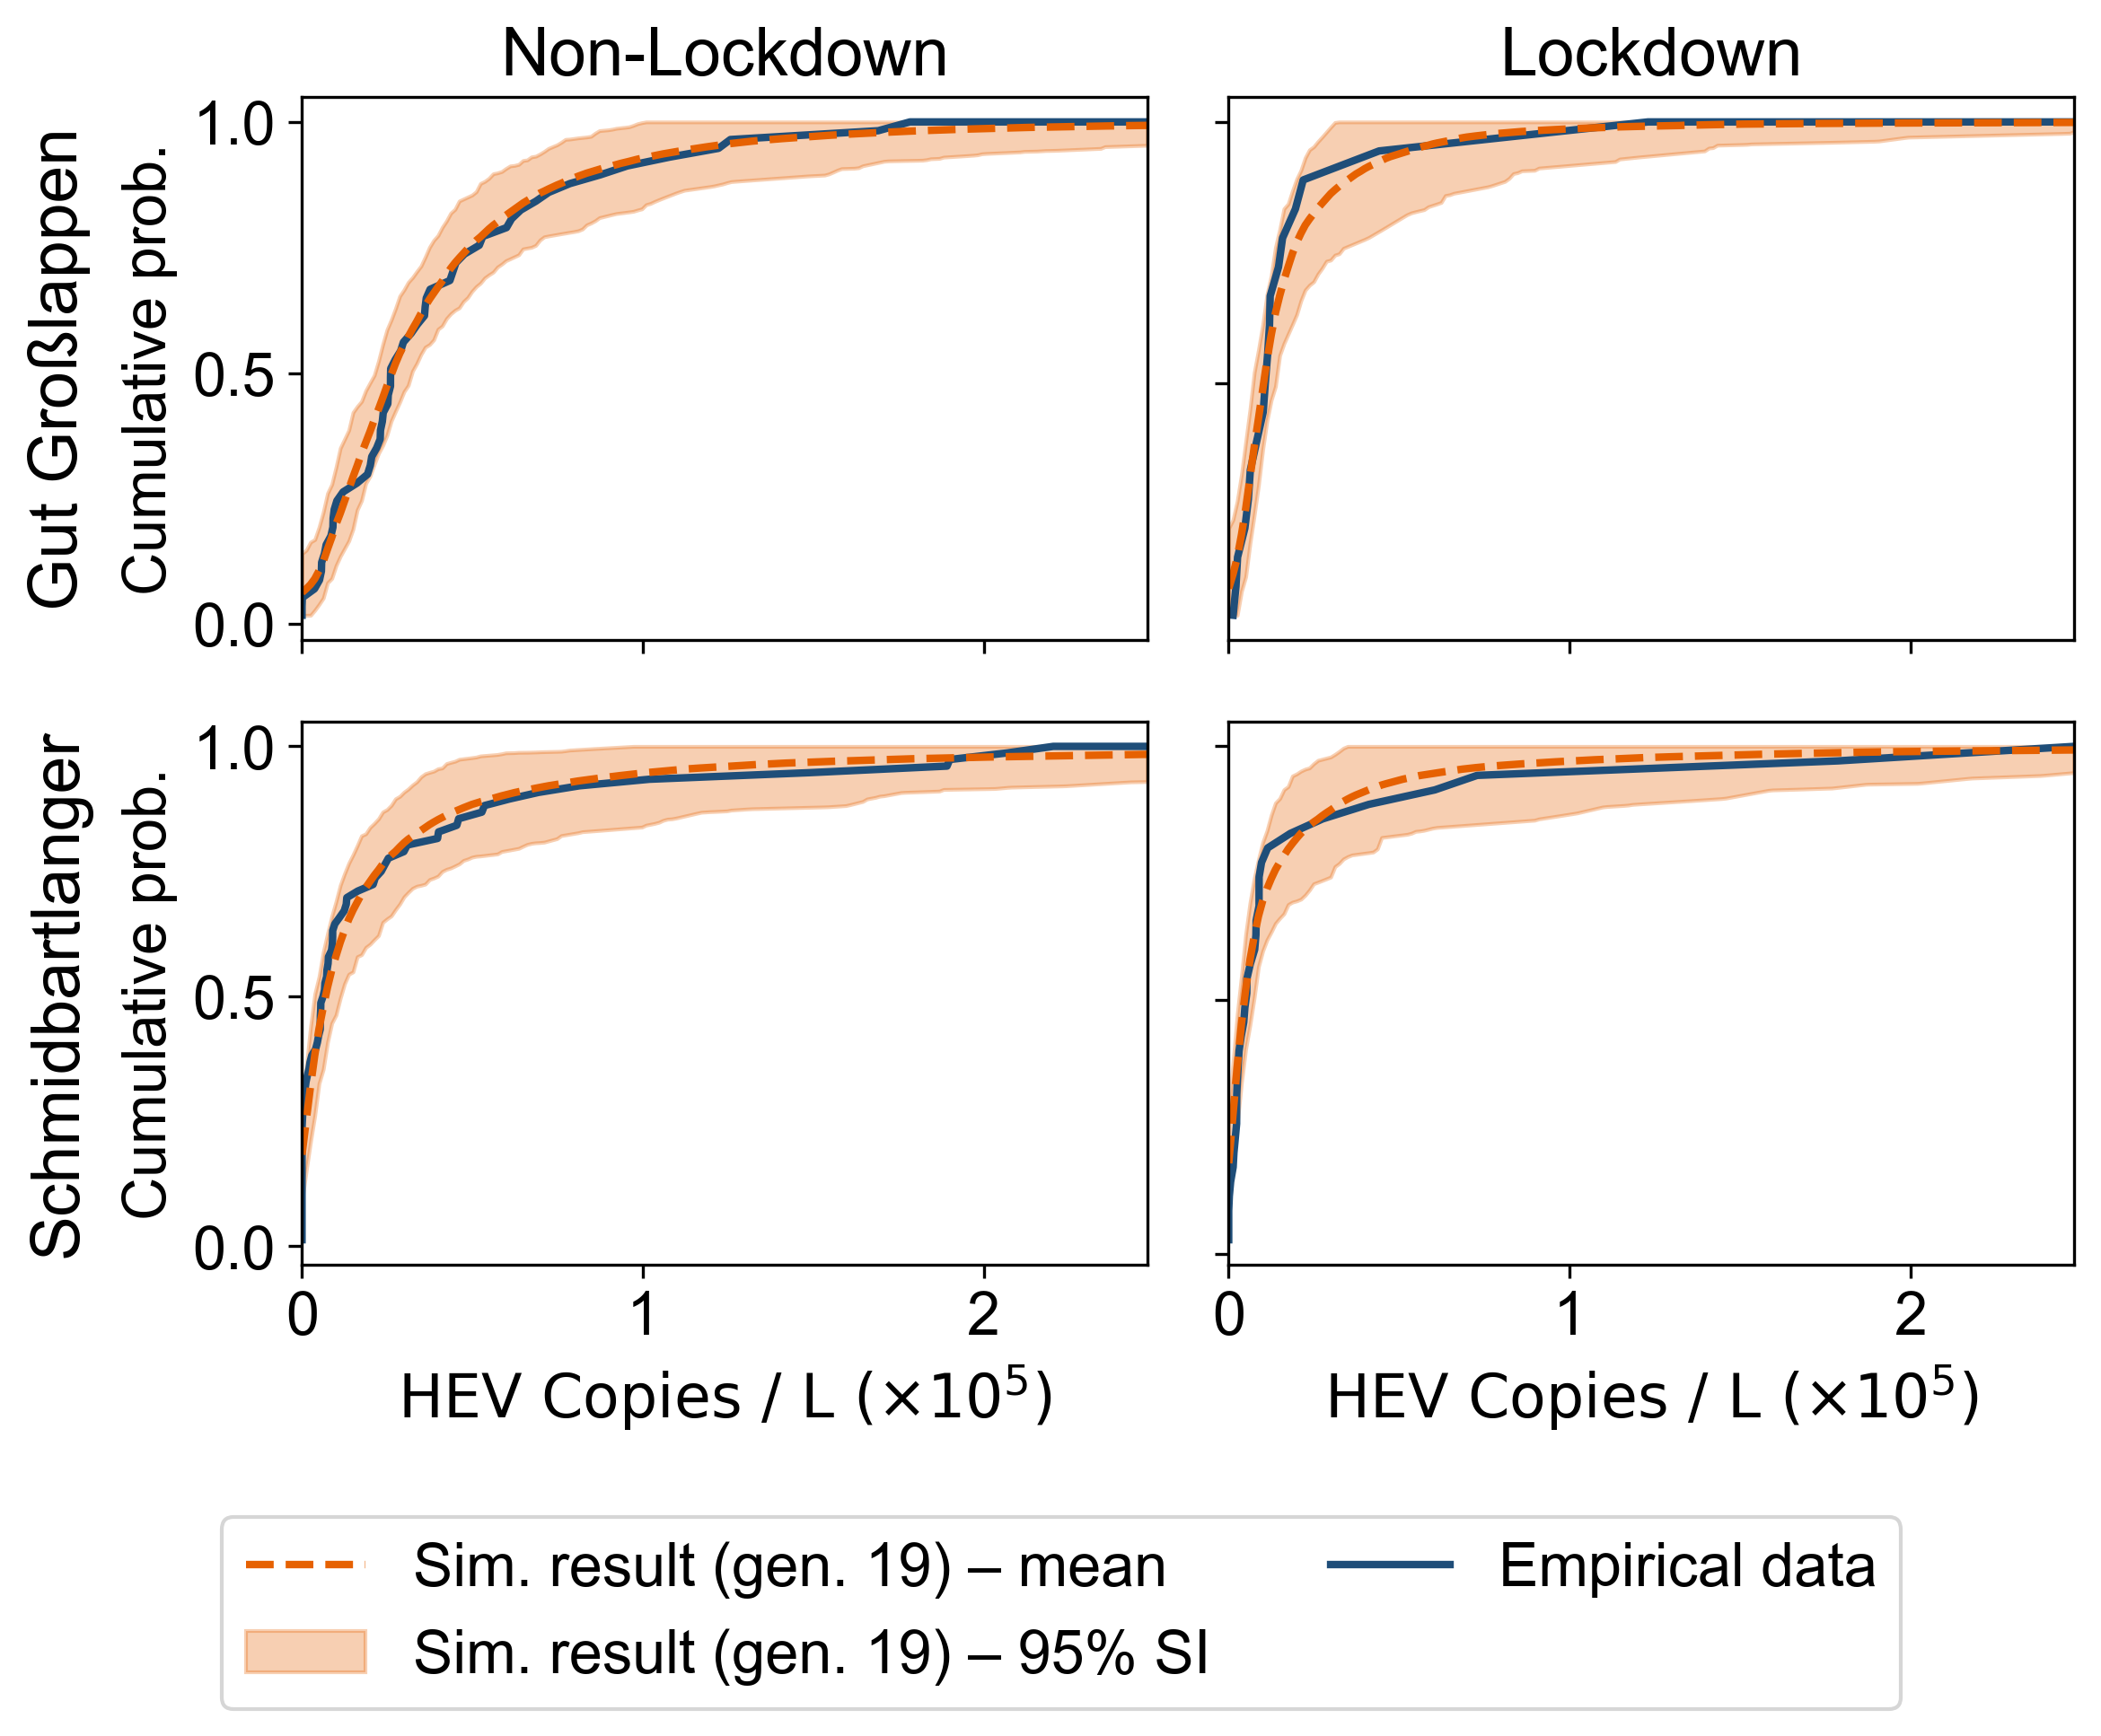

In [91]:
plt.style.use('default')
set_fontsize()

locs = ['24h Probe', 'Schmidbartlanger']
categories = ['Non-Emergency', 'Emergency']
x_min, x_max = obs['HEV_c'].min() / 1e5, obs['HEV_c'].max() / 1e5
x_grid = np.linspace(x_min, x_max, 200)

fig, axes = plt.subplots(figsize = (8,6), nrows=2, ncols=2, dpi=300)

for i, name in enumerate(locs):
    for j, cat in enumerate(categories):
        ax = axes[i, j]

        subset = obs[(obs['Name'] == name) & (obs['Category'] == cat)].copy()
        subset["HEV_c"] = subset["HEV_c"] / 1e5
        x = np.sort(subset['HEV_c'])
        y = np.arange(1, len(x) + 1) / len(x)
        x = np.append(x, x_max)
        y = np.append(y, 1.0)
        ax.plot(x, y, color=darkblue, linewidth=2, label="Empirical data")
        #mean_emp = subset["HEV_c"].median()
        #ax.axvline(mean_emp, color=darkblue, linestyle=":", linewidth=1.2, label=None)

        sim_sub = sim[(sim["Name"] == name) & (sim["Category"] == cat)]
        if not sim_sub.empty:
            lower, mean, upper = compute_ecdf_band(sim_sub, x_grid, x_max)
            ax.fill_between(x_grid, lower, upper, color=orange, alpha=0.3, label="Sim. result (gen. 19) – 95% SI")
            ax.plot(x_grid, mean, color=orange, linewidth=2, linestyle='--', label="Sim. result (gen. 19) – mean")
            #mean_sim = sim_sub.groupby("particle")["ww_scaled"].median().median()
            #ax.axvline(mean_sim, color=orange, linestyle=":", linewidth=1.2, label=None)
            
            #text_str = "\n".join([rf"Emp. med. = ${mean_emp*10:.1f} \times 10^{4}$", rf"Sim. med. = ${mean_sim*10:.1f} \times 10^{4}$"])
            #ax.text(0.97, 0.05, text_str, transform=ax.transAxes, ha='right', va='bottom', fontsize=16, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))

        ax.set_title("")

        if i == 0:
            ax.set_xlabel("")
            ax.set_xticklabels([])
            ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)
        else:
            ax.set_xlabel(r"$\mathrm{HEV\ Copies\ / \ L\ ( \times 10^{5})}$")
            ax.ticklabel_format(axis='x', style='plain')

        if j == 1:
            ax.set_ylabel("")
            ax.set_yticklabels([])
            ax.tick_params(axis='y', which='both', left=True, right=False, labelleft=False)
        else:
            ax.set_ylabel("Cumulative prob.")

        ax.set_xlim(x_min, x_max)

display_names = {'24h Probe': 'Gut Großlappen', 'Schmidbartlanger': 'Schmidbartlanger', 'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}

for j, cat in enumerate(categories):
    axes[0, j].set_title(display_names.get(cat, cat))

for i, name in enumerate(locs):
    axes[i, 0].annotate(
        display_names.get(name, name),
        xy=(-0.25, 0.5),
        xycoords='axes fraction',
        ha='right',
        va='center',
        rotation=90,
        fontsize=18
    )

handles, labels = axes[0,0].get_legend_handles_labels()
order = [2, 1, 0] 
handles = [handles[i] for i in order]
labels = [labels[i] for i in order]

fig.legend(
    handles, labels,
    loc='lower center',
    ncol=2,           
    frameon=True,
    bbox_to_anchor=(0.5, -0.1) 
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(f"{plot_path}/dist-fits.png", dpi=300, bbox_inches='tight')
plt.show()

In [92]:
def posterior_to_plot_1d(pop_num, x_var, x_min, x_max, num_x):
    df, w = history.get_distribution(0, pop_num)
    post = pyabc.visualization.kde.kde_1d(df, w, x = x_var, xmin = x_min, xmax = x_max, numx = num_x)
    post_list = list(map(list, zip(*list(post))))
    return pd.DataFrame(post_list, columns = ["x", "prob"])

In [93]:
pop0_ld = posterior_to_plot_1d(pop_num = 0, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop6_ld = posterior_to_plot_1d(pop_num = 6, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop12_ld = posterior_to_plot_1d(pop_num = 12, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop16_ld = posterior_to_plot_1d(pop_num = 16, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop17_ld = posterior_to_plot_1d(pop_num = 17, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop18_ld = posterior_to_plot_1d(pop_num = 18, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)

pop0_scaleG = posterior_to_plot_1d(pop_num = 0, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop6_scaleG = posterior_to_plot_1d(pop_num = 6, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop12_scaleG = posterior_to_plot_1d(pop_num = 12, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop16_scaleG = posterior_to_plot_1d(pop_num = 16, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop17_scaleG = posterior_to_plot_1d(pop_num = 17, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop18_scaleG = posterior_to_plot_1d(pop_num = 18, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)

pop0_scaleS = posterior_to_plot_1d(pop_num = 0, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop6_scaleS = posterior_to_plot_1d(pop_num = 6, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop12_scaleS = posterior_to_plot_1d(pop_num = 12, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop16_scaleS = posterior_to_plot_1d(pop_num = 16, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop17_scaleS = posterior_to_plot_1d(pop_num = 17, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop18_scaleS = posterior_to_plot_1d(pop_num = 18, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)

pop0_noise1G = posterior_to_plot_1d(pop_num = 0, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop6_noise1G = posterior_to_plot_1d(pop_num = 6, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop12_noise1G = posterior_to_plot_1d(pop_num = 12, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop16_noise1G = posterior_to_plot_1d(pop_num = 16, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop17_noise1G = posterior_to_plot_1d(pop_num = 17, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop18_noise1G = posterior_to_plot_1d(pop_num = 18, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)

pop0_noise1S = posterior_to_plot_1d(pop_num = 0, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop6_noise1S = posterior_to_plot_1d(pop_num = 6, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop12_noise1S = posterior_to_plot_1d(pop_num = 12, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop16_noise1S = posterior_to_plot_1d(pop_num = 16, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop17_noise1S = posterior_to_plot_1d(pop_num = 17, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop18_noise1S = posterior_to_plot_1d(pop_num = 18, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)

pop0_noise2G = posterior_to_plot_1d(pop_num = 0, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop6_noise2G = posterior_to_plot_1d(pop_num = 6, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop12_noise2G = posterior_to_plot_1d(pop_num = 12, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop16_noise2G = posterior_to_plot_1d(pop_num = 16, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop17_noise2G = posterior_to_plot_1d(pop_num = 17, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop18_noise2G = posterior_to_plot_1d(pop_num = 18, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)

pop0_noise2S = posterior_to_plot_1d(pop_num = 0, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop6_noise2S = posterior_to_plot_1d(pop_num = 6, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop12_noise2S = posterior_to_plot_1d(pop_num = 12, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop16_noise2S = posterior_to_plot_1d(pop_num = 16, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop17_noise2S = posterior_to_plot_1d(pop_num = 17, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop18_noise2S = posterior_to_plot_1d(pop_num = 18, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)

In [94]:
def plot_group(ax, dfs, xticks=None, xticklabels=None):
    set_fontsize()
    colors = [lightest_grey, lightgrey, medium_grey, darkgrey, darkest_grey, orange]
    for d, c in zip(dfs, colors):
        sns.lineplot(data=d, x="x", y="prob", color=c, ax=ax)

    max_y = max(df['prob'].max() for df in dfs) * 1.05
    min_y = min(df['prob'].min() for df in dfs)

    ax.set(ylim=(min_y, max_y))
    ax.set_yticks([min_y, (min_y + max_y) / 2, max_y])
    ax.set(xlabel=None, ylabel=None, yticklabels=[])

    if xticks is not None:
        ax.set_xticks(xticks)
    if xticklabels is not None:
        ax.set_xticklabels(xticklabels)

    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(x=0, y=0)

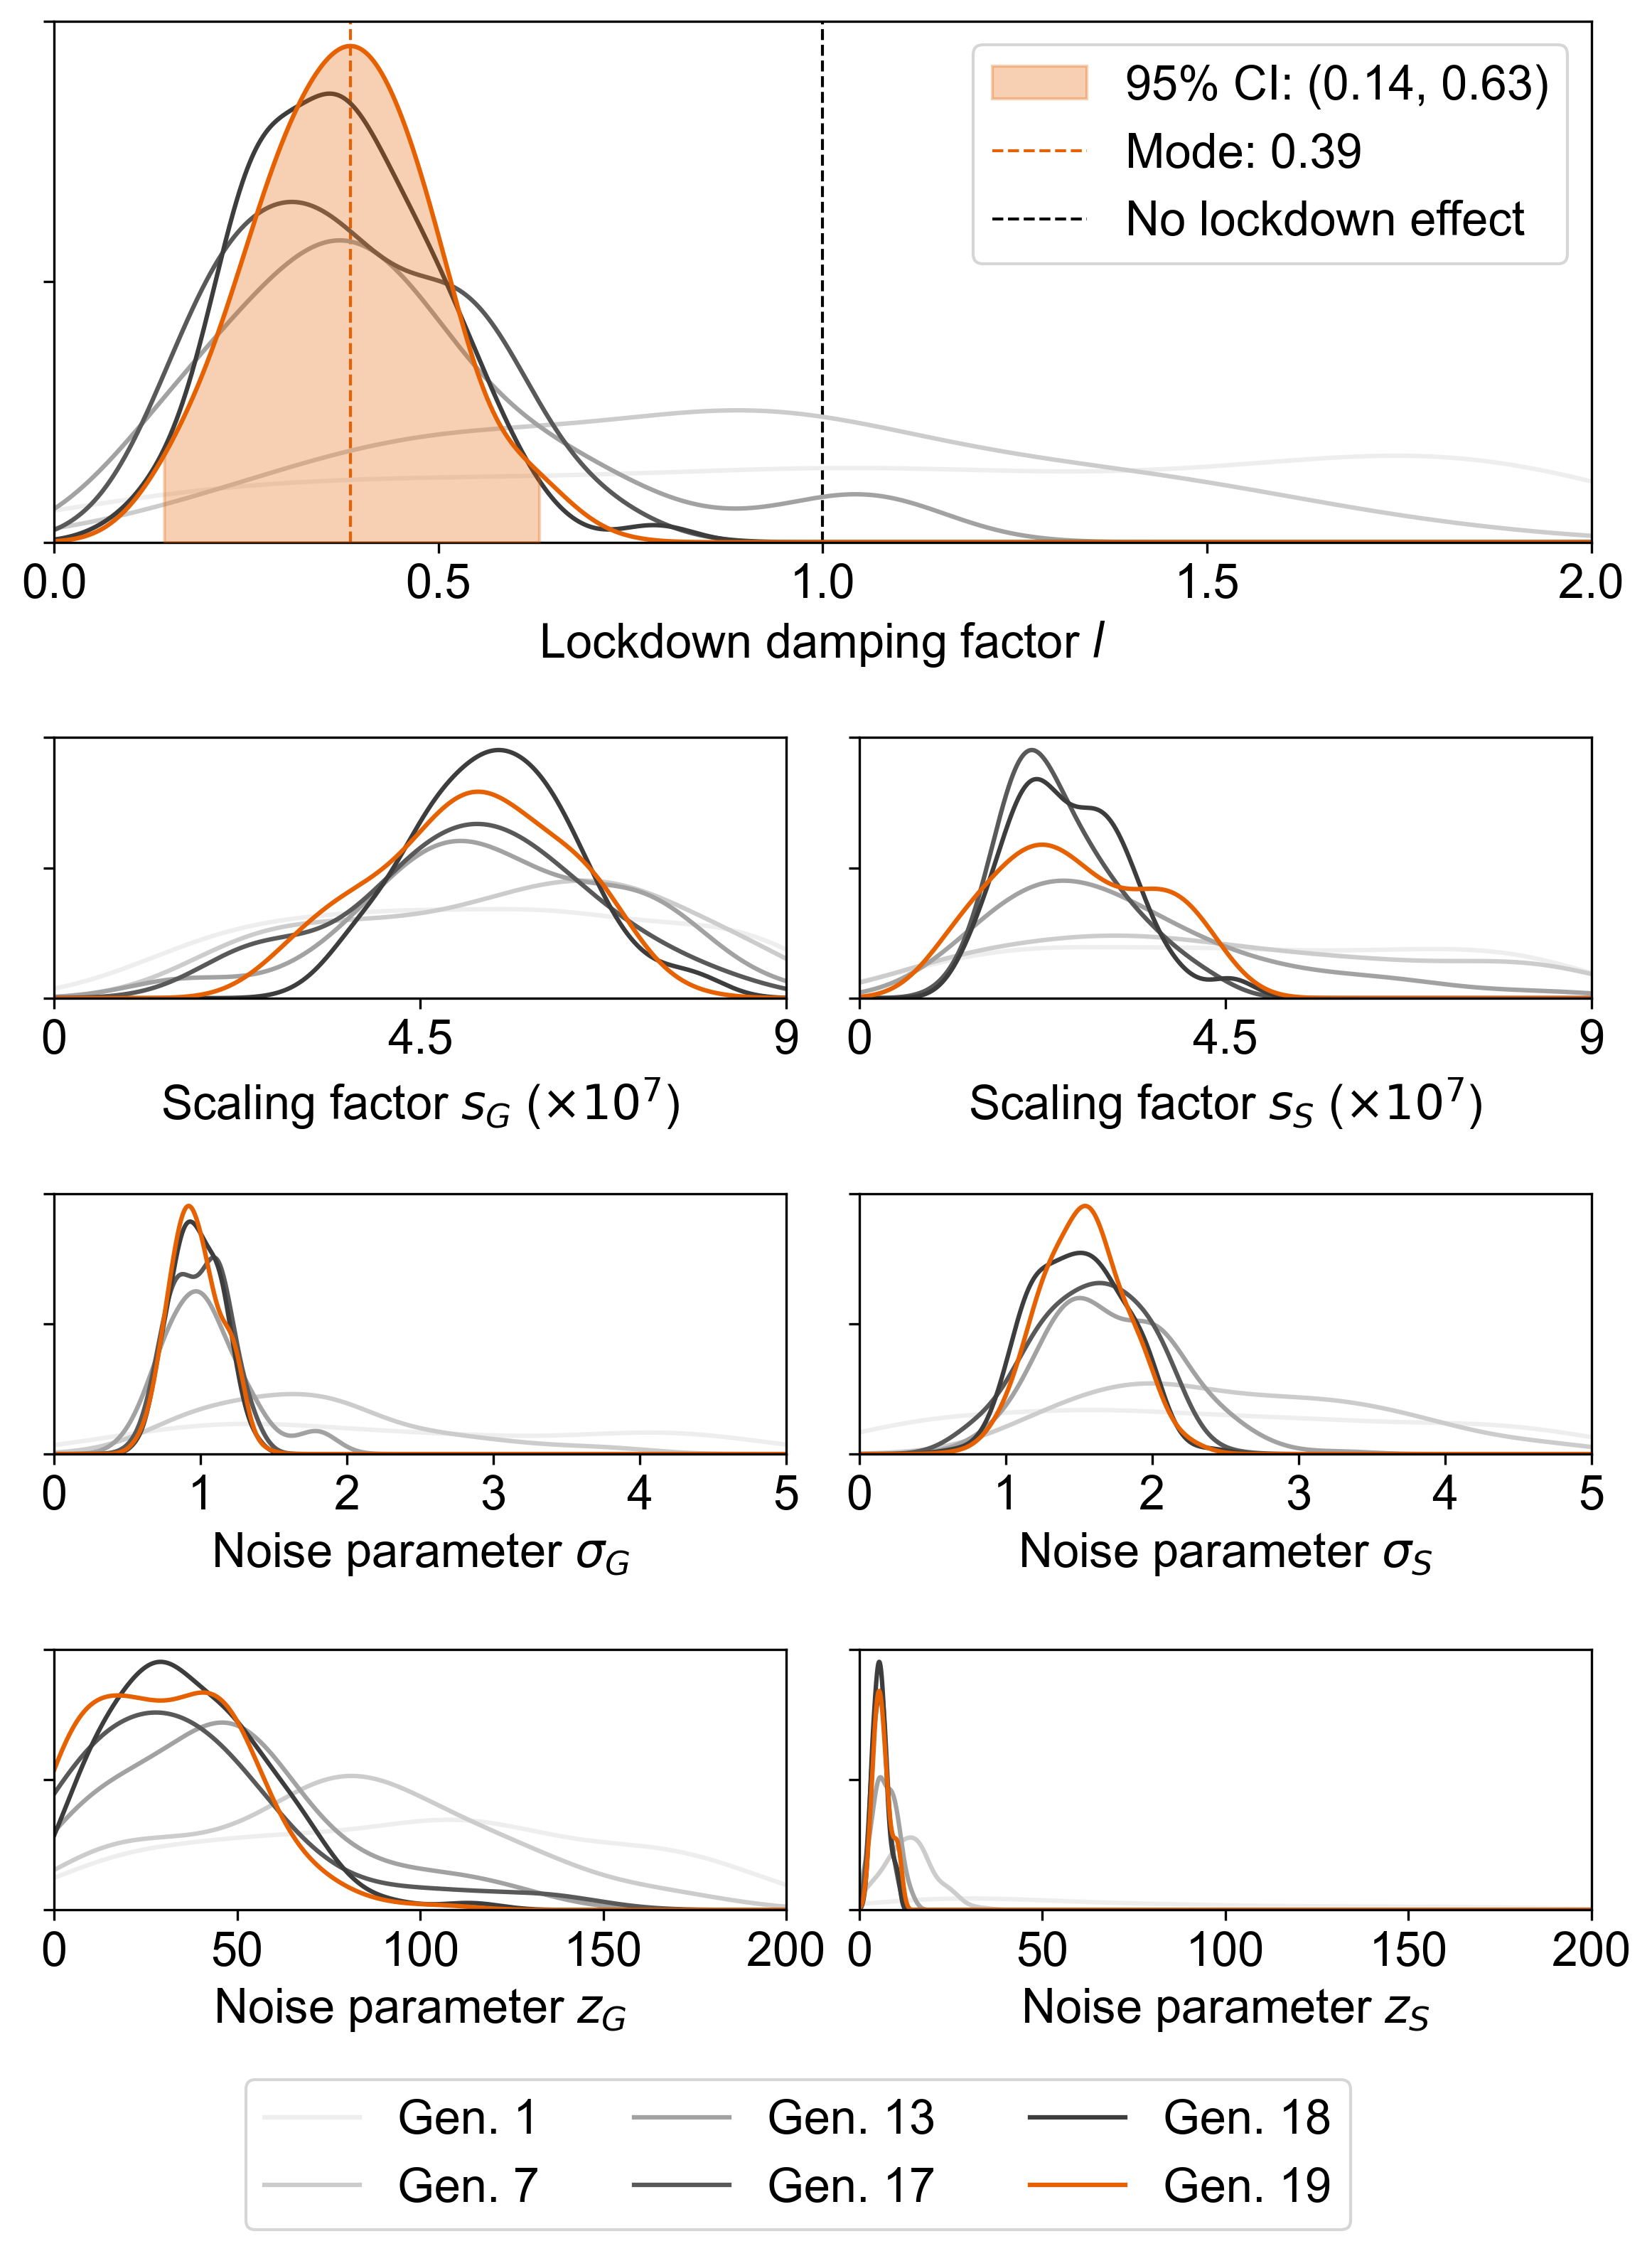

In [95]:
fig = plt.figure(figsize=(9.3, 11.5), dpi=300)
gs = GridSpec(nrows=4, ncols=2, figure=fig, hspace=0.6, wspace=0.1, height_ratios=[2, 1, 1, 1])

ax_ld = fig.add_subplot(gs[0, :])

ax_scaleG   = fig.add_subplot(gs[1, 0])
ax_scaleS   = fig.add_subplot(gs[1, 1])
ax_noise1G  = fig.add_subplot(gs[2, 0])
ax_noise1S  = fig.add_subplot(gs[2, 1])
ax_noise2G  = fig.add_subplot(gs[3, 0])
ax_noise2S  = fig.add_subplot(gs[3, 1])

x = pop18_ld['x'].to_numpy()
y = pop18_ld['prob'].to_numpy()
x_mode = x[np.argmax(y)]
cdf = np.cumsum(y)
cdf = cdf / cdf[-1]
q_lo, q_hi = np.interp([0.025, 0.975], cdf, x)

mask = (pop18_ld["x"] >= q_lo) & (pop18_ld["x"] <= q_hi)

ax_ld.fill_between(pop18_ld["x"][mask], pop18_ld["prob"][mask], color=orange, alpha=0.3, label=f'95% CI: ({q_lo:.2f}, {q_hi:.2f})', zorder=5)
ax_ld.axvline(x= x_mode, color=orange, linestyle='--', linewidth=1, label = f"Mode: {x_mode:.2f}")
ax_ld.axvline(x=1, color='black', linestyle='--', linewidth=1, label = "No lockdown effect")
plot_group(ax_ld, [pop0_ld, pop6_ld, pop12_ld, pop16_ld, pop17_ld, pop18_ld],  xticks=[0, 0.5, 1, 1.5, 2])

plot_group(ax_scaleG, [pop0_scaleG, pop6_scaleG, pop12_scaleG, pop16_scaleG, pop17_scaleG, pop18_scaleG],
           xticks=[0, 45_000_000, 90_000_000],
           xticklabels=['0', '4.5', '9'])
plot_group(ax_scaleS, [pop0_scaleS, pop6_scaleS, pop12_scaleS, pop16_scaleS, pop17_scaleS, pop18_scaleS],
           xticks=[0, 45_000_000, 90_000_000],
           xticklabels=['0', '4.5', '9'])

plot_group(ax_noise1G, [pop0_noise1G, pop6_noise1G, pop12_noise1G, pop16_noise1G, pop17_noise1G, pop18_noise1G])
plot_group(ax_noise1S, [pop0_noise1S, pop6_noise1S, pop12_noise1S, pop16_noise1S, pop17_noise1S, pop18_noise1S])
plot_group(ax_noise2G, [pop0_noise2G, pop6_noise2G, pop12_noise2G, pop16_noise2G, pop17_noise2G, pop18_noise2G])
plot_group(ax_noise2S, [pop0_noise2S, pop6_noise2S, pop12_noise2S, pop16_noise2S, pop17_noise2S, pop18_noise2S])

ax_ld.set_xlabel(r"Lockdown damping factor $l$")
ax_scaleG.set_xlabel(r"Scaling factor $s_G$ ($\times 10^7$)")
ax_scaleS.set_xlabel(r"Scaling factor $s_S$ ($\times 10^7$)")
ax_noise1G.set_xlabel(r"Noise parameter $\sigma_G$")
ax_noise1S.set_xlabel(r"Noise parameter $\sigma_S$")
ax_noise2G.set_xlabel(r"Noise parameter $z_G$")
ax_noise2S.set_xlabel(r"Noise parameter $z_S$")

gen_handles = [
    mlines.Line2D([], [], color=lightest_grey, label='Gen. 1'),
    mlines.Line2D([], [], color=lightgrey, label='Gen. 7'),
    mlines.Line2D([], [], color=medium_grey, label='Gen. 13'),
    mlines.Line2D([], [], color=darkgrey, label='Gen. 17'),
    mlines.Line2D([], [], color=darkest_grey, label='Gen. 18'),
    mlines.Line2D([], [], color=orange, label='Gen. 19')
]

# Add joint legend
fig.legend(handles=gen_handles,
           loc='lower center',
           ncol=3,
           bbox_to_anchor=(0.5, -0.03),
           frameon=True)

plt.savefig(f"{plot_path}/posteriors.png", dpi=300, bbox_inches='tight')
plt.show()

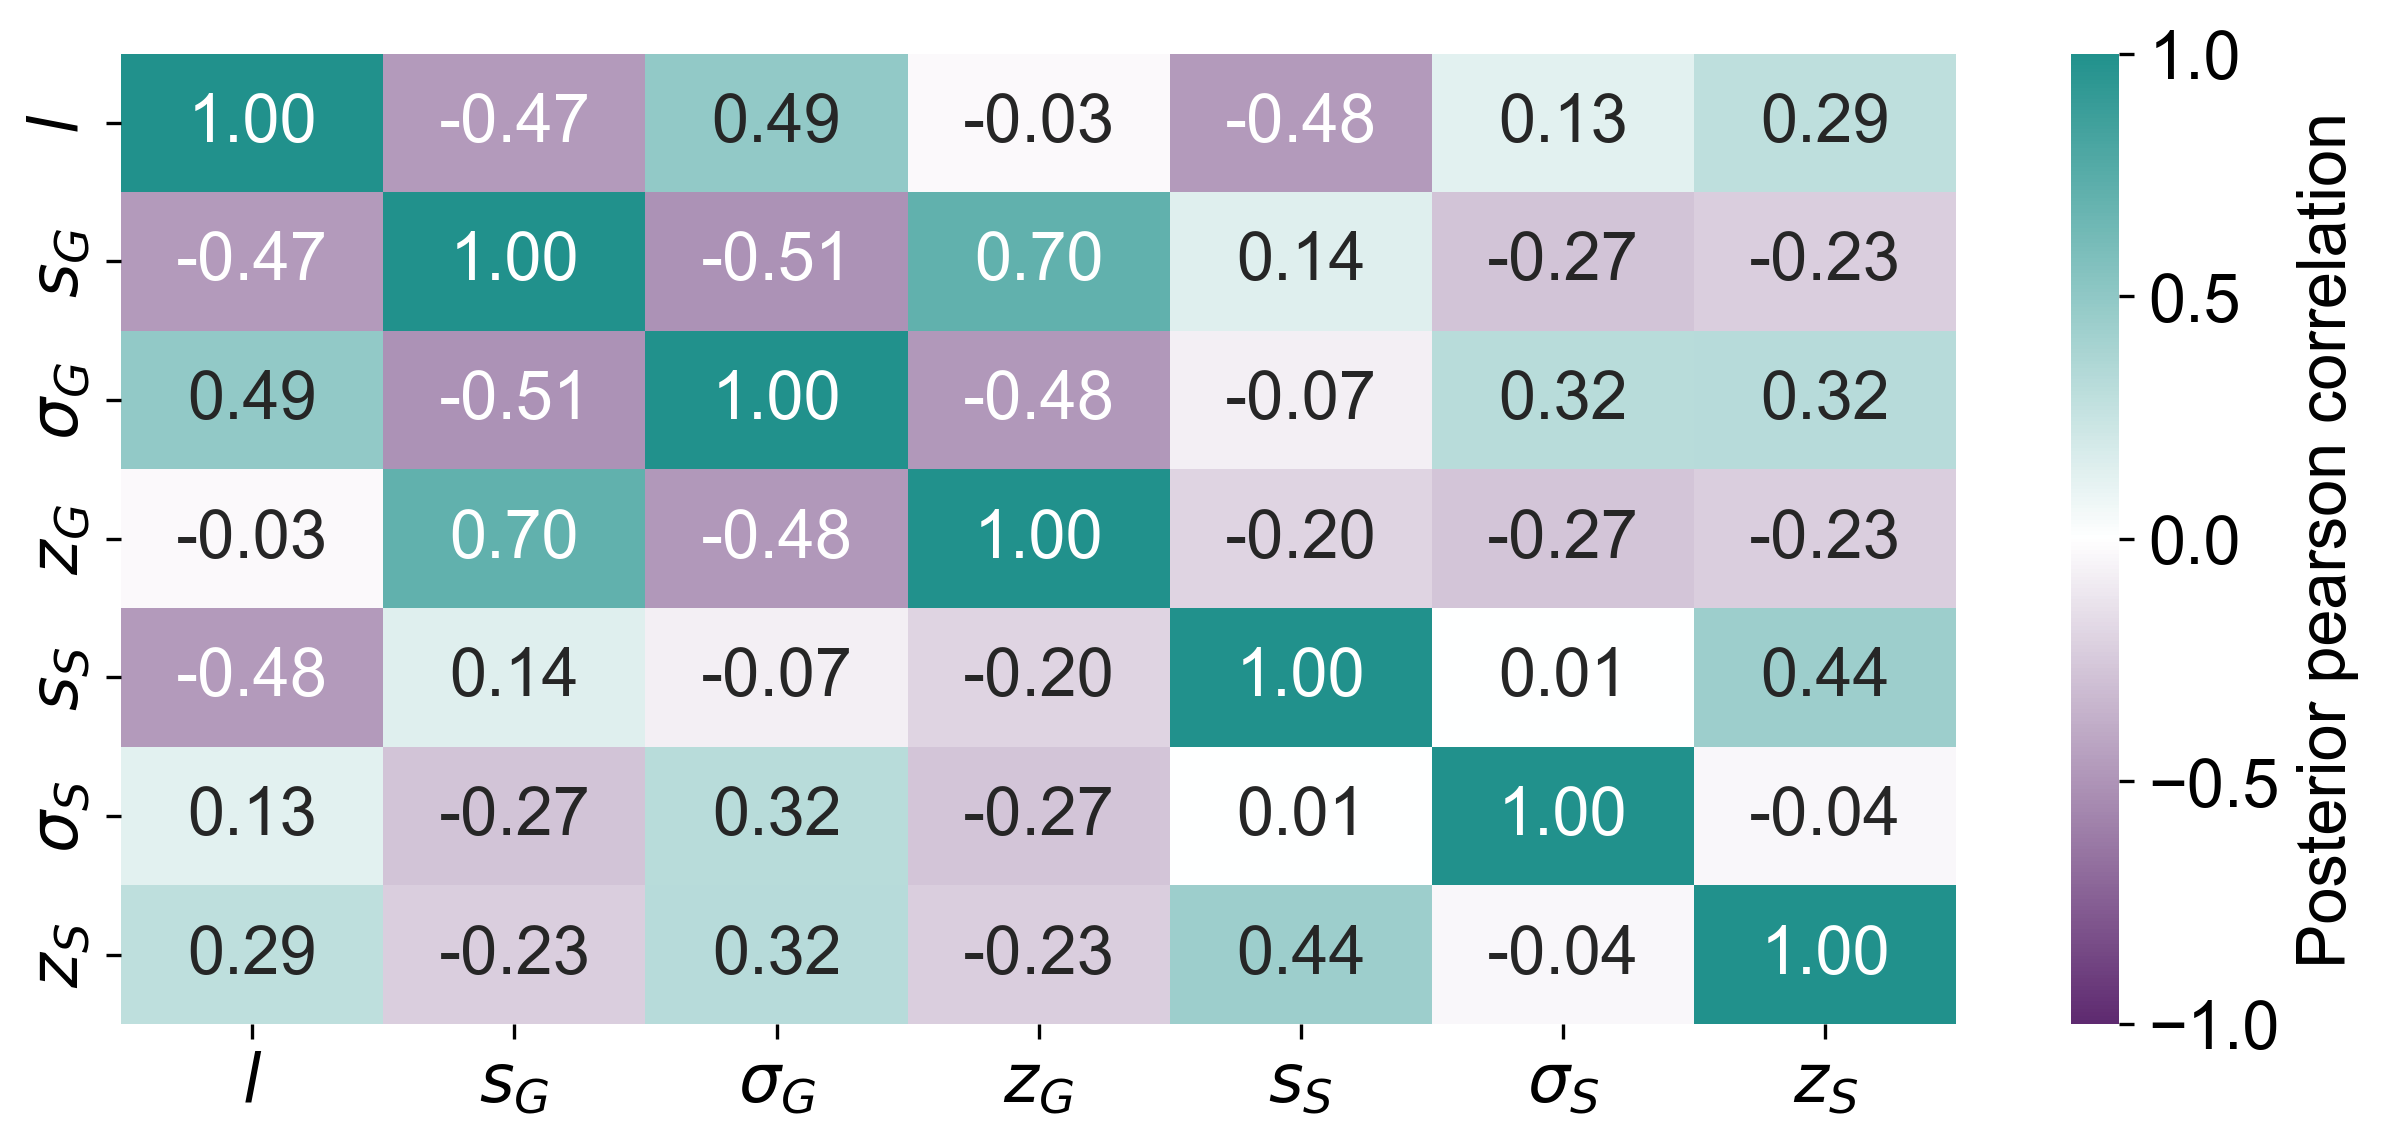

In [96]:
plt.style.use('default')
set_fontsize()

p = history.max_t
df_post, w_post = history.get_distribution(0, p)
params = [c for c in df_post.columns]
df_plot = df_post.copy()
n_samples = 3000 if len(df_plot) > 3000 else len(df_plot)
df_plot = df_plot.sample(n=n_samples, replace=True, weights=w_post, random_state=42)

plt.figure(figsize=(8.43,4.1), dpi=300)

rename_map = {
    "ld": r"$l$",
    "scaleG": r"$s_G$",
    "noise1G": r"$\sigma_G$",
    "noise2G": r"$z_G$",
    "scaleS": r"$s_S$",
    "noise1S": r"$\sigma_S$",
    "noise2S": r"$z_S$",
}

ordered_params = list(rename_map.keys())
corr = df_plot[params].corr()
corr = corr.loc[ordered_params, ordered_params]
corr.index = [rename_map[c] for c in corr.index]
corr.columns = [rename_map[c] for c in corr.columns]

custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "blue_maroon", [purple, "white", teal]
)

sns.heatmap(corr, annot=True, fmt=".2f", square=False, cmap=custom_cmap, vmin = -1, vmax = 1,
            cbar_kws={"label": "Posterior pearson correlation", "ticks": [-1, -0.5, 0, 0.5, 1]})
plt.tight_layout()
plt.savefig(f"{plot_path}/param_corr_heatmap.png", dpi=300)
plt.show()